# 57 · Behavior cloning from (privileged) state: low offline loss, imperfect online success

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse import TableTop, ScriptedExpert, evaluate, wilson
from vlacourse.features import privileged_obs, PRIV_DIM

torch.set_num_threads(4)

def collect_state_demos(env, n, seed=0):
    X, Y, ep_id = [], [], []
    for ep in range(n):
        env.reset(seed=seed + ep); ex = ScriptedExpert(env, seed=ep, speed=np.random.default_rng(ep).uniform(0.6, 1.0)); done = False
        while not done:
            x = privileged_obs(env); a = ex.act()
            X.append(x); Y.append(a); ep_id.append(ep)
            _, _, done, _ = env.step(a)
    return np.array(X), np.array(Y), np.array(ep_id)

class MLPPolicy(nn.Module):
    def __init__(self, d_in=PRIV_DIM, d_out=7, hidden=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, d_out))
    def forward(self, x):
        return self.net(x)

def fit(X, Y, epochs=60, lr=1e-3, val_frac=0.1, seed=0):
    torch.manual_seed(seed)
    mx, sx = X.mean(0), X.std(0) + 1e-6
    my, sy = Y.mean(0), Y.std(0) + 1e-6
    Xn, Yn = torch.tensor((X - mx) / sx), torch.tensor((Y - my) / sy)
    n_val = int(len(X) * val_frac); perm = torch.randperm(len(X)); va, tr = perm[:n_val], perm[n_val:]
    model = MLPPolicy(); opt = torch.optim.Adam(model.parameters(), lr=lr)
    curve = []
    for e in range(epochs):
        for idx in tr[torch.randperm(len(tr))].split(256):
            loss = nn.functional.mse_loss(model(Xn[idx]), Yn[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            curve.append((loss.item(), nn.functional.mse_loss(model(Xn[va]), Yn[va]).item()))
    return model, (mx, sx, my, sy), np.array(curve)

class StatePolicy:
    def __init__(self, env, model, stats):
        self.env, self.model, (self.mx, self.sx, self.my, self.sy) = env, model, stats
    def act(self, obs):
        x = (privileged_obs(self.env) - self.mx) / self.sx
        with torch.no_grad():
            y = self.model(torch.tensor(x, dtype=torch.float32)).numpy()
        a = y * self.sy + self.my
        a[6] = float(a[6] > 0.5)
        return a

In [2]:
env = TableTop(cameras=(), seed=0)
t0 = time.time()
X, Y, E = collect_state_demos(env, 200)
print(f"{len(X)} (state, action) pairs from 200 expert episodes in {time.time() - t0:.0f}s; feature dim {X.shape[1]}")

8442 (state, action) pairs from 200 expert episodes in 10s; feature dim 20


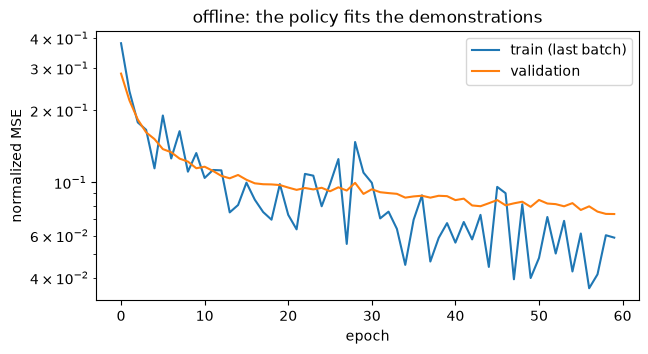

In [3]:
model, stats, curve = fit(X, Y)
plt.figure(figsize=(7, 3.5)); plt.semilogy(curve[:, 0], label="train (last batch)"); plt.semilogy(curve[:, 1], label="validation")
plt.xlabel("epoch"); plt.ylabel("normalized MSE"); plt.legend(); plt.title("offline: the policy fits the demonstrations"); plt.show()

In [4]:
res = evaluate(env, StatePolicy(env, model, stats), n_episodes=100, seed=50_000)
print(f"online success: {res['success']:.2f}  95% CI [{res['ci'][0]:.2f}, {res['ci'][1]:.2f}]  per task: {res['per_task']}")
print(f"offline validation MSE (normalized): {curve[-1, 1]:.4f}")

online success: 0.50  95% CI [0.40, 0.60]  per task: {'pick': 0.9714285714285714, 'stack': 0.34375, 'place': 0.15151515151515152}
offline validation MSE (normalized): 0.0738


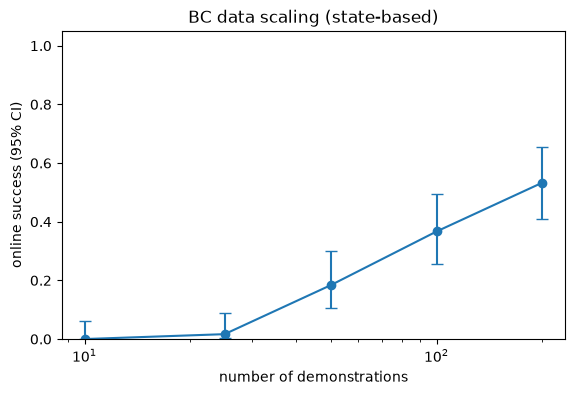

In [5]:
sizes = [10, 25, 50, 100, 200]
rates, pols, runs = [], {}, {}
for n in sizes:
    m, st, _ = fit(X[E < n], Y[E < n])
    pols[n] = StatePolicy(env, m, st)
    r = evaluate(env, pols[n], n_episodes=60, seed=50_000); runs[n] = r
    rates.append((r["success"], *r["ci"]))
rates = np.array(rates)
plt.figure(figsize=(6.5, 4)); plt.errorbar(sizes, rates[:, 0], yerr=[rates[:, 0] - rates[:, 1], rates[:, 2] - rates[:, 0]], marker="o", capsize=4)
plt.xscale("log"); plt.xlabel("number of demonstrations"); plt.ylabel("online success (95% CI)"); plt.ylim(0, 1.05); plt.title("BC data scaling (state-based)"); plt.show()

In [6]:
fails = [e for e in res["episodes"] if not e["success"]]
print("failures by task:", {t: sum(1 for e in fails if e["task"] == t) for t in ["pick", "place", "stack"]})
print("failure episodes mostly hit the 200-step limit:", np.mean([e["steps"] >= 200 for e in fails]).round(2) if fails else "n/a")

failures by task: {'pick': 1, 'place': 28, 'stack': 21}
failure episodes mostly hit the 200-step limit: 1.0


### Watch it: 10 demonstrations vs 200
The same network and the same episode. Only the amount of data differs.

In [7]:
from vlacourse import showcase as sc
sc.compare(env, {"trained on 10 demos": pols[10], "trained on 200 demos": pols[200]}, seed=sc.pick_seed(runs[200], runs[10], 50_000), title="57 BC with 10 vs 200 demos")

57 BC with 10 vs 200 demos: trained on 10 demos: failed | trained on 200 demos: success


[False, True]